In [5]:
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import warnings
warnings.filterwarnings("ignore")

from wordcloud import WordCloud
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


**Load Data**

In [6]:
true = pd.read_csv('/content/True.csv', encoding='latin-1')
fake = pd.read_csv('/content/Fake.csv', encoding='latin-1')

In [7]:
# Add labels
fake['label'] = 0 # Fake
true['label'] = 1 # Real

**Merge & shuffle**

In [8]:
#Merge $ shuffle
df = pd.concat([fake,true],ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Fake articles : {len(fake)}")
print(f"Real articles : {len(true)}")
print(f"Total rows : {len(df)}")
print(df.head())

Fake articles : 23481
Real articles : 21417
Total rows : 44898
                                               title  \
0  Ben Stein Calls Out 9th Circuit Court: Committ...   
1  Trump drops Steve Bannon from National Securit...   
2  Puerto Rico expects U.S. to lift Jones Act shi...   
3   OOPS: Trump Just Accidentally Confirmed He Le...   
4  Donald Trump heads for Scotland to reopen a go...   

                                                text       subject  \
0  21st Century Wire says Ben Stein, reputable pr...       US_News   
1  WASHINGTON (Reuters) - U.S. President Donald T...  politicsNews   
2  (Reuters) - Puerto Rico Governor Ricardo Rosse...  politicsNews   
3  On Monday, Donald Trump once again embarrassed...          News   
4  GLASGOW, Scotland (Reuters) - Most U.S. presid...  politicsNews   

                  date  label  
0    February 13, 2017      0  
1       April 5, 2017       1  
2  September 27, 2017       1  
3         May 22, 2017      0  
4       June 24, 20

**Exploratory Data Analysis (EDA)**

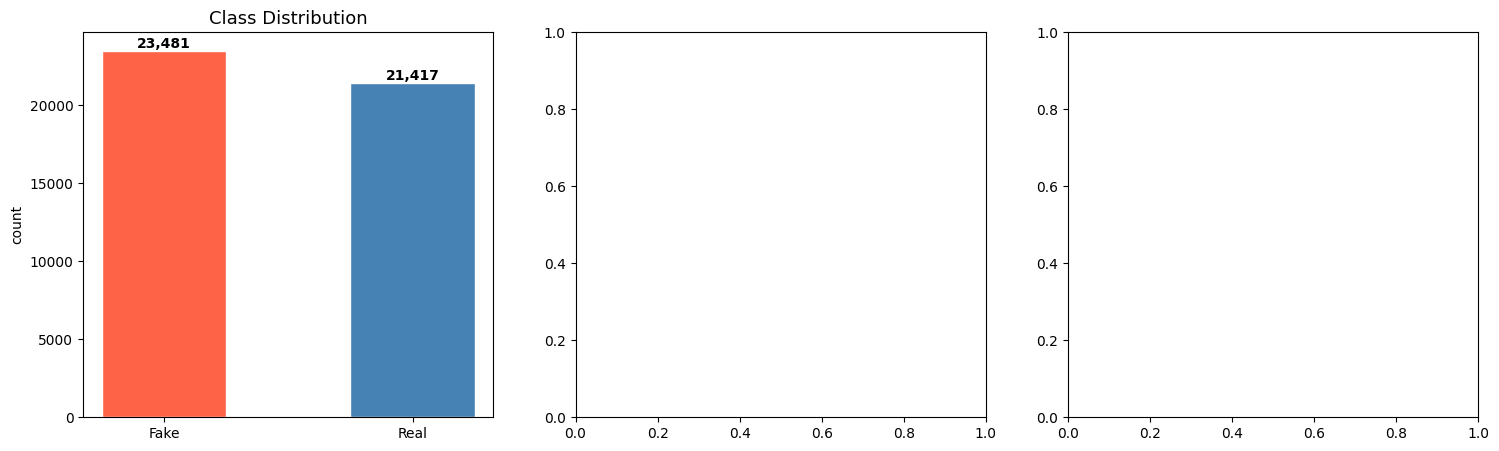

In [9]:
fig, axes = plt.subplots(1,3, figsize=(18,5))

# Plot 1: Class Distribution
counts = df['label'].map({0:'Fake', 1:'Real'}).value_counts()
axes[0].bar(counts.index, counts.values,
            color=['tomato','steelblue'], edgecolor='white',
width=0.5)
axes[0].set_title('Class Distribution', fontsize=13)
axes[0].set_ylabel('count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v+200, f'{v:,}', ha='center', fontweight='bold')



In [10]:
# Plot 2: Subject Distribution
subj = df.groupby(['subject','label']).size().unstack(fill_value=0)
subj.plot(kind='bar', ax=axes[1], color=['tomato','steelblue'], edgecolor='white')
axes[1].set_title('Articles per Subject', fontsize=13)
axes[1].legend(['FAKE','REAL'])
axes[1].tick_params(axis='x', rotation=30)
plt.show()

**Clean Text**

In [11]:
from tqdm.notebook import tqdm
tqdm.pandas()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\[.*?\]',               ' ', text)
    text = re.sub(r'[^a-z\s]',             ' ', text)
    text = re.sub(r'\s+',                  ' ', text)
    tokens = [w for w in text.split()
              if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

df['combined'] = df['title'].fillna('') + ' ' + df['text'].fillna('')
df['combined'] = df['combined'].progress_apply(clean_text)  # shows progress bar
df = df[df['combined'].str.strip() != ''].reset_index(drop=True)
print(f"Sample: {df['combined'].iloc[0][:150]}")

  0%|          | 0/44898 [00:00<?, ?it/s]

Sample: ben stein calls circuit court committed coup tat constitution century wire says ben stein reputable professor pepperdine university also hollywood fam


In [12]:
#  Sample to avoid browser freeze
fake_text = ' '.join(df[df['label'] == 0]['combined'].sample(5000, random_state=42))
real_text = ' '.join(df[df['label'] == 1]['combined'].sample(5000, random_state=42))

**TF-IDF Vectorization**

In [13]:
X = df['combined'].values
y = df['label'].values

tfidf = TfidfVectorizer(
    max_features = 10000,     # top 10,000 words
    ngram_range  = (1, 2),    # unigrams + bigrams
    sublinear_tf = True,      # log normalization
    min_df       = 3,         # ignore very rare words
    max_df       = 0.95       # ignore very common words
)

X_tfidf = tfidf.fit_transform(X)

print(f"TF-IDF shape: {X_tfidf.shape}")
print(f"   → {X_tfidf.shape[0]:,} articles × {X_tfidf.shape[1]:,} features")

TF-IDF shape: (44889, 10000)
   → 44,889 articles × 10,000 features


**Train / Test Split**

In [14]:
X = df['combined'].values
y = df['label'].values

# TF-IDF
tfidf = TfidfVectorizer(
    max_features = 10000,
    ngram_range  = (1, 2),
    sublinear_tf = True,
    min_df       = 3,
    max_df       = 0.95
)
X_tfidf = tfidf.fit_transform(X)

print(f" TF-IDF shape: {X_tfidf.shape}")

# Check class counts before splitting
from collections import Counter
label_counts = Counter(y)
print(f"Label counts: {label_counts}")


min_class_count = min(label_counts.values())

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y,
    test_size    = 0.20,
    random_state = 42,
    stratify     = y if min_class_count >= 2 else None
)

print(f"   Training : {X_train.shape[0]:,} samples")
print(f"   Testing  : {X_test.shape[0]:,} samples")


 TF-IDF shape: (44889, 10000)
Label counts: Counter({np.int64(0): 23472, np.int64(1): 21417})
   Training : 35,911 samples
   Testing  : 8,978 samples


In [15]:
print(f"   Train labels: {Counter(y_train)}")
print(f"   Test  labels: {Counter(y_test)}")

   Train labels: Counter({np.int64(0): 18777, np.int64(1): 17134})
   Test  labels: Counter({np.int64(0): 4695, np.int64(1): 4283})


**Model Creation**

****

In [16]:
nb_model = MultinomialNB(alpha=0.1)
nb_model.fit(X_train, y_train)



MultinomialNB(alpha=0.1)

In [17]:
print(" Naive Bayes model trained!")
print(f"   Alpha (smoothing) = 0.1")
print(f"   Classes = {nb_model.classes_}  →  0=FAKE, 1=REAL")

 Naive Bayes model trained!
   Alpha (smoothing) = 0.1
   Classes = [0 1]  →  0=FAKE, 1=REAL


**Evaluate Model**

In [18]:
y_pred  = nb_model.predict(X_test)
y_proba = nb_model.predict_proba(X_test)[:, 1]

In [19]:
y_pred

array([1, 1, 0, ..., 1, 0, 0])

In [20]:
y_proba

array([7.57223723e-01, 9.99992603e-01, 3.85438426e-02, ...,
       9.73015714e-01, 3.13231212e-06, 2.96375774e-01])

In [21]:
acc = accuracy_score(y_test, y_pred)
print(f" Accuracy : {acc * 100:.2f}%\n")

 Accuracy : 95.91%



In [22]:
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['FAKE','REAL']))


Classification Report:
              precision    recall  f1-score   support

        FAKE       0.96      0.96      0.96      4695
        REAL       0.95      0.96      0.96      4283

    accuracy                           0.96      8978
   macro avg       0.96      0.96      0.96      8978
weighted avg       0.96      0.96      0.96      8978



In [23]:
#  3-fold  + parallel jobs
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_scores = cross_val_score(nb_model, X_tfidf, y, cv=cv,
                             scoring='accuracy', n_jobs=-1)
print(f" 3-Fold CV Accuracy: {cv_scores.mean()*100:.2f}% ± {cv_scores.std()*100:.2f}%")

 3-Fold CV Accuracy: 95.86% ± 0.11%


**confusion_matrix**

****

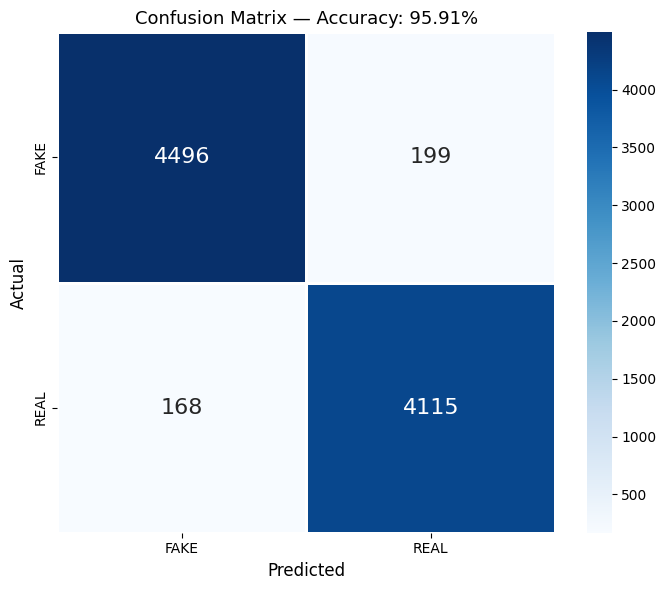

 True  Positives (REAL→REAL) : 4,115
   True  Negatives (FAKE→FAKE) : 4,496
   False Positives (FAKE→REAL) : 199
   False Negatives (REAL→FAKE) : 168


In [24]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['FAKE','REAL'],
            yticklabels=['FAKE','REAL'],
            linewidths=2, linecolor='white',
            annot_kws={"size": 16})
plt.title(f'Confusion Matrix — Accuracy: {acc*100:.2f}%', fontsize=13)
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

print(f" True  Positives (REAL→REAL) : {tp:,}")
print(f"   True  Negatives (FAKE→FAKE) : {tn:,}")
print(f"   False Positives (FAKE→REAL) : {fp:,}")
print(f"   False Negatives (REAL→FAKE) : {fn:,}")

**ROC Curve**

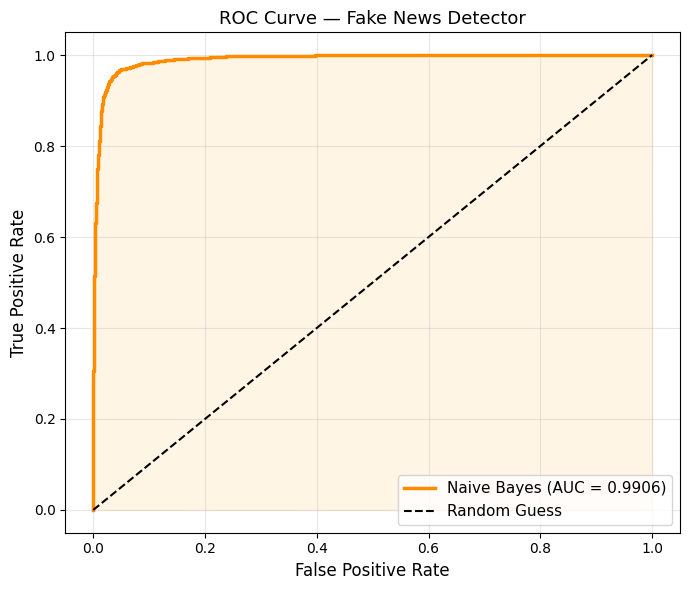

 AUC Score : 0.9906


In [25]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2.5,
         label=f'Naive Bayes (AUC = {roc_auc:.4f})')
plt.fill_between(fpr, tpr, alpha=0.1, color='orange')
plt.plot([0,1],[0,1],'k--', lw=1.5, label='Random Guess')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate',  fontsize=12)
plt.title('ROC Curve — Fake News Detector', fontsize=13)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

print(f" AUC Score : {roc_auc:.4f}")

**Top Keywords**

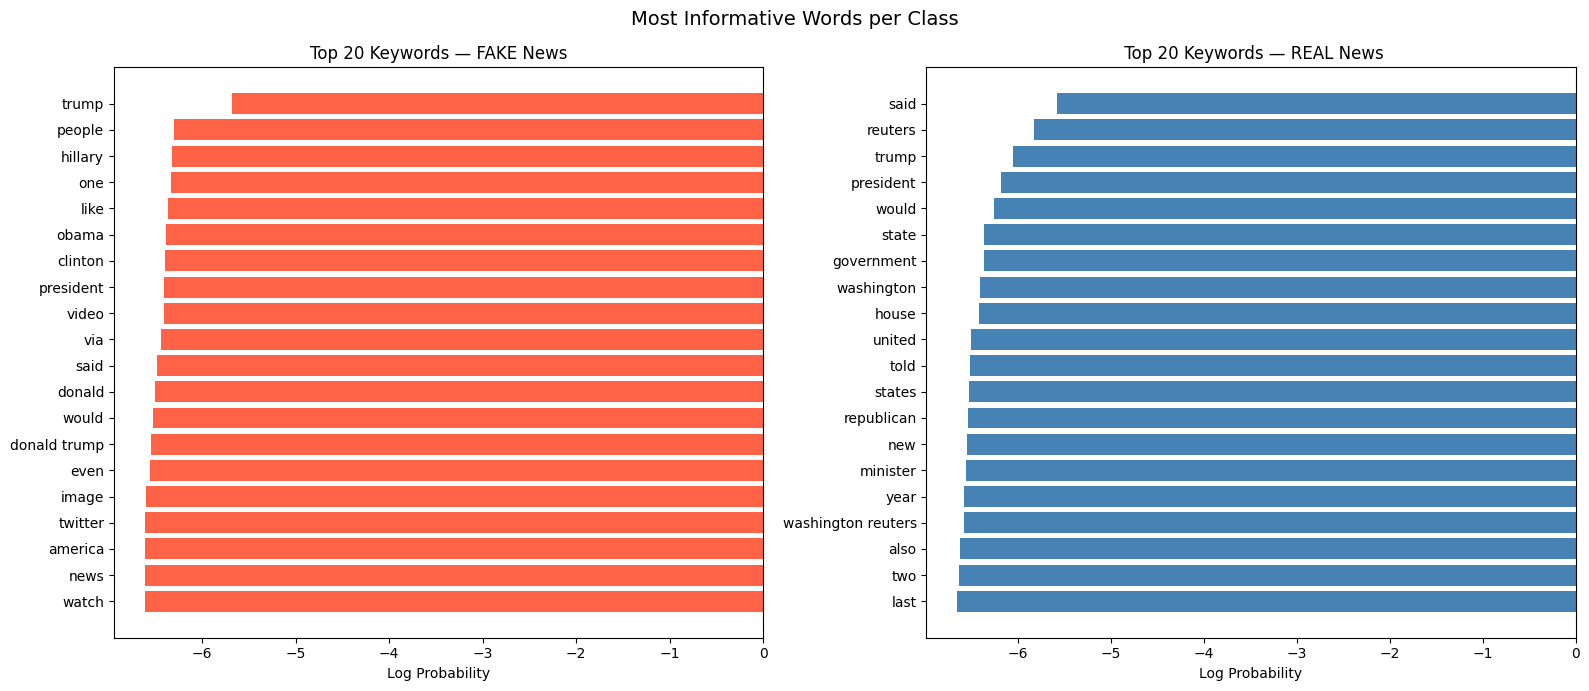

 Top keywords plotted!


In [26]:
feature_names = tfidf.get_feature_names_out()
log_prob      = nb_model.feature_log_prob_
top_n         = 20

top_fake_idx = np.argsort(log_prob[0])[-top_n:][::-1]
top_real_idx = np.argsort(log_prob[1])[-top_n:][::-1]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh([feature_names[i] for i in top_fake_idx[::-1]],
             log_prob[0][top_fake_idx[::-1]], color='tomato')
axes[0].set_title('Top 20 Keywords — FAKE News', fontsize=12)
axes[0].set_xlabel('Log Probability')

axes[1].barh([feature_names[i] for i in top_real_idx[::-1]],
             log_prob[1][top_real_idx[::-1]], color='steelblue')
axes[1].set_title(' Top 20 Keywords — REAL News', fontsize=12)
axes[1].set_xlabel('Log Probability')

plt.suptitle('Most Informative Words per Class', fontsize=14)
plt.tight_layout()
plt.savefig("top_keywords.png", dpi=150)
plt.show()
print(" Top keywords plotted!")

**Save Model**

In [27]:
with open("nb_model.pkl", "wb") as f:
    pickle.dump(nb_model, f)

with open("tfidf.pkl", "wb") as f:
    pickle.dump(tfidf, f)

print("Model saved  → nb_model.pkl")
print(" Vectorizer saved → tfidf.pkl")

Model saved  → nb_model.pkl
 Vectorizer saved → tfidf.pkl


**Predict News**

In [28]:
def predict_news(title, text=""):
    combined = clean_text(title + ' ' + text)
    vec      = tfidf.transform([combined])
    pred     = nb_model.predict(vec)[0]
    proba    = nb_model.predict_proba(vec)[0]

    label = "FAKE NEWS" if pred == 0 else " REAL NEWS"
    print(f"\n  Title      : {title[:70]}")
    print(f"  Prediction : {label}")
    print(f"  FAKE prob  : {proba[0]*100:.1f}%")
    print(f"  REAL prob  : {proba[1]*100:.1f}%")
    print(f"  Confidence : {max(proba)*100:.1f}%")

# ── Test it
predict_news("10 U.S. Navy Sailors Held by Iranian Military",
             "21st Century Wire says As 21WIRE predicted...")

predict_news("U.S. budget fight looms, Republicans flip fiscal script",
             "WASHINGTON (Reuters) The head of a conservative Republican...")

predict_news("Scientists Discover Cure for All Diseases with One Pill!",
             "Anonymous sources claim the government is hiding this miracle cure...")


  Title      : 10 U.S. Navy Sailors Held by Iranian Military
  Prediction : FAKE NEWS
  FAKE prob  : 99.6%
  REAL prob  : 0.4%
  Confidence : 99.6%

  Title      : U.S. budget fight looms, Republicans flip fiscal script
  Prediction :  REAL NEWS
  FAKE prob  : 18.2%
  REAL prob  : 81.8%
  Confidence : 81.8%

  Title      : Scientists Discover Cure for All Diseases with One Pill!
  Prediction : FAKE NEWS
  FAKE prob  : 79.3%
  REAL prob  : 20.7%
  Confidence : 79.3%
